In [22]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [23]:
conn = sqlite3.connect("expense_tracker.db")

cursor = conn.cursor()

print("Database Connected")

Database Connected


In [24]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS transactions(
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    date TEXT,
    type TEXT,
    category TEXT,
    amount REAL,
    note TEXT
)
""")

conn.commit()

print("Table Created")

Table Created


In [25]:
def add_transaction(date, trans_type, category, amount, note):
    
    cursor.execute("""
    INSERT INTO transactions
    (date,type,category,amount,note)
    VALUES(?,?,?,?,?)
    """,
    (date, trans_type, category, amount, note))
    
    conn.commit()
    
    print("Transaction Added")

In [26]:
add_transaction(
    "2026-06-17",
    "Income",
    "Salary",
    50000,
    "Monthly Salary"
)

Transaction Added


In [27]:
add_transaction(
    "2026-06-17",
    "Expense",
    "Food",
    500,
    "Lunch"
)

Transaction Added


In [28]:
def view_transactions():
    
    query = """
    SELECT * FROM transactions
    """
    
    df = pd.read_sql(query, conn)
    
    return df

In [29]:
view_transactions()

,id,date,type,category,amount,note
0,1,2026-06-17,Income,Salary,50000.0,Monthly Salary
1,2,2026-06-17,Expense,Food,500.0,Lunch
2,3,2026-06-01,Expense,Transport,300.0,Bus Fare
3,4,2026-06-02,Expense,Shopping,1200.0,T Shirt
4,5,2026-06-03,Expense,Food,700.0,Dinner
5,6,2026-06-05,Income,Freelancing,10000.0,Client Payment
6,7,2026-06-17,Income,Salary,50000.0,Monthly Salary
7,8,2026-06-17,Expense,Food,500.0,Lunch


In [30]:
def financial_summary():
    
    df = pd.read_sql(
        "SELECT * FROM transactions",
        conn
    )
    
    income = df[df["type"]=="Income"]["amount"].sum()
    
    expense = df[df["type"]=="Expense"]["amount"].sum()
    
    balance = income - expense
    
    print("Total Income :", income)
    print("Total Expense :", expense)
    print("Balance :", balance)

In [31]:
financial_summary()

Total Income : 110000.0
Total Expense : 3200.0
Balance : 106800.0


In [32]:
def monthly_report():
    
    query = """
    SELECT
    substr(date,1,7) as Month,
    SUM(amount) as Total
    FROM transactions
    GROUP BY Month
    """
    
    df = pd.read_sql(query, conn)
    
    return df

In [33]:
monthly_report()

,Month,Total
0,2026-06,113200.0


In [34]:
def category_analysis():
    
    query = """
    SELECT
    category,
    SUM(amount) as Total
    FROM transactions
    WHERE type='Expense'
    GROUP BY category
    """
    
    df = pd.read_sql(query, conn)
    
    return df

In [35]:
category_analysis()

,category,Total
0,Food,1700.0
1,Shopping,1200.0
2,Transport,300.0


In [36]:
def expense_pie_chart():
    
    df = category_analysis()
    
    plt.figure(figsize=(6,6))
    
    plt.pie(
        df["Total"],
        labels=df["category"],
        autopct="%1.1f%%"
    )
    
    plt.title("Expense Distribution")
    
    plt.show()

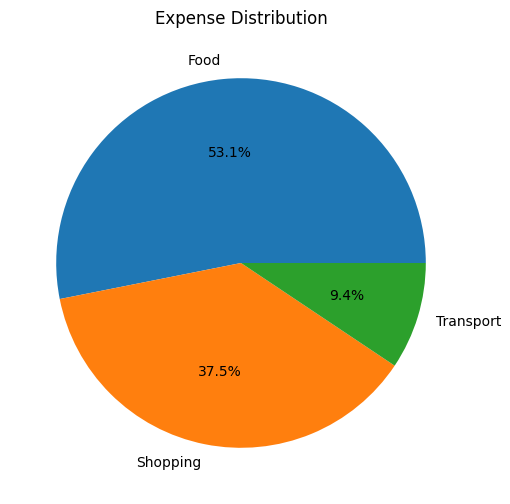

In [37]:
expense_pie_chart()

In [38]:
def expense_bar_chart():
    
    df = category_analysis()
    
    plt.figure(figsize=(8,5))
    
    plt.bar(
        df["category"],
        df["Total"]
    )
    
    plt.title("Expense by Category")
    
    plt.xlabel("Category")
    
    plt.ylabel("Amount")
    
    plt.show()

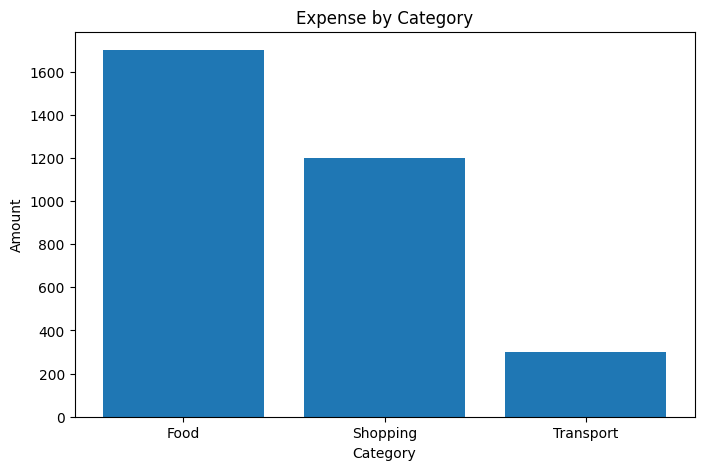

In [39]:
expense_bar_chart()

In [40]:
def export_csv():
    
    df = pd.read_sql(
        "SELECT * FROM transactions",
        conn
    )
    
    df.to_csv(
        "transactions.csv",
        index=False
    )
    
    print("CSV Exported")

In [41]:
export_csv()

CSV Exported


In [42]:
add_transaction(
    "2026-06-01",
    "Expense",
    "Transport",
    300,
    "Bus Fare"
)

add_transaction(
    "2026-06-02",
    "Expense",
    "Shopping",
    1200,
    "T Shirt"
)

add_transaction(
    "2026-06-03",
    "Expense",
    "Food",
    700,
    "Dinner"
)

add_transaction(
    "2026-06-05",
    "Income",
    "Freelancing",
    10000,
    "Client Payment"
)

Transaction Added
Transaction Added
Transaction Added
Transaction Added
